# A Depth-Observability Admission Criterion for UAV Visual-Inertial Odometry: experiments

Companion notebook of the paper *A Depth-Observability Admission Criterion for UAV Visual-Inertial Odometry*
(G. Briia, I. Turkin, O. Liubimov; ISEAS / ISUN-AI 2026).

A landmark is admitted to the filter update only if the camera displacement over the track, b, divided by the
triangulated depth, d, exceeds a bound derived from the tracking noise:

$$ b/d \ge \theta, \qquad \theta = k\,\sigma_{px}/f, \qquad k\,\sigma_{px} = 2.5\ \text{px} $$

(θ = 0.0055 for EuRoC, 0.0131 for the TUM-VI fisheye camera). The notebook runs a monocular MSCKF on 17 public
sequences (EuRoC MAV: 11, TUM-VI room1–room6) under different admission settings and writes every table and number of the
paper to a `results/` folder. The estimator code is embedded below (the same files as `msckf/` and `experiments/` of
the repository), so the notebook runs on its own. Every run is deterministic and single-threaded.

| Tier | Runs | Settings | Used for |
|---|---|---|---|
| **A** | 68 | strict 1° threshold; loose 0.3° threshold; loose + criterion (b/d); loose + criterion with the transverse baseline (b⊥/d); original start | per-sequence results, cost, admission chain |
| **B** | 68 | loose + criterion at kσ_px = 1, 1.5, 3.5 and 5 px | sensitivity to kσ_px |
| **C** | 102 | strict, loose and loose + criterion with the first frame delayed by 0.1 s and 0.2 s | Table 1 and the paired tests over 51 runs |
| **D** | 578 | thresholds 0°, 0.1°, 0.2°, 0.5° and 0.7° without and with the criterion, and 1° with the criterion, each from three starts; 1.5° without the criterion | Table 2 (threshold sweep) |

In the code the criterion is called the *gate*. Run tags: `std` = strict 1° threshold, `agg` = loose 0.3° threshold,
`par<deg>` = another threshold; `none` / `ratio` / `perp` = no criterion / b/d / b⊥/d; `_s0.1`, `_s0.2` = delayed start;
`_ks<px>` = another value of kσ_px.

**Runtime.** About 4–6 CPU-minutes per run. Tiers A and C (170 runs, enough for Table 1) take about 2 h on an 8-core
runtime; all 816 runs take about 7 h. Finished runs are cached as JSON files and skipped on the next start, so the
notebook can be stopped and restarted at any time (**Runtime → Run all** again).

**How to run.**
1. Put the datasets in a folder (section 4 lists the accepted layouts and the download pages).
2. Set `DRIVE_ROOT` in section 1: the folder that holds `Datasets/`. The notebook writes to `DRIVE_ROOT/depth-observability-criterion/`
   (`runs/` and `results/`). On Colab the default is Google Drive, so that the cache survives the session; a path under
   `/content/` works without Drive. Locally (Jupyter) the default is the current folder, or set the environment
   variable `DG_DRIVE_ROOT`.
3. Choose the tiers and run all cells.

To rebuild the tables from finished runs only, point `DRIVE_ROOT` at the folder that holds `depth-observability-criterion/runs/` and run
all cells: nothing is recomputed. If only `results/summary_all_runs.csv` is available (as shipped in the repository),
the tables that need per-run ATE values are still produced, and the ones that need per-candidate logs are skipped.

## 1. Settings

In [1]:
#@title Settings
import os, sys, json, time, glob, shutil, subprocess
DRIVE_ROOT = "/content/drive/MyDrive/Adaptive VIO for UAV Navigation"   #@param {type:"string"}
DATASETS_DIR = "Datasets"               #@param {type:"string"}
OUTPUT_DIR = "depth-observability-criterion"   #@param {type:"string"}
TIERS = "ABCD"          #@param ["A", "AC", "ABC", "ABCD"]
JOBS = 0                #@param {type:"integer"}
# JOBS = 0 means one run per CPU core
IN_COLAB = "google.colab" in sys.modules
DRIVE_ROOT = os.environ.get("DG_DRIVE_ROOT", DRIVE_ROOT)
OUTPUT_DIR = os.environ.get("DG_OUTPUT_DIR", OUTPUT_DIR)
if not IN_COLAB and DRIVE_ROOT.startswith("/content/"):
    DRIVE_ROOT = os.path.abspath(".")                         # local Jupyter default: the current folder
if IN_COLAB and DRIVE_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
DATASETS = os.path.join(DRIVE_ROOT, DATASETS_DIR)             # raw data (read only)
STUDY = os.path.join(DRIVE_ROOT, OUTPUT_DIR)                  # everything this notebook writes
RUNS, RESULTS = os.path.join(STUDY, "runs"), os.path.join(STUDY, "results")
LOCAL = "/content" if IN_COLAB else os.path.abspath("dg_local")
CODE, DATA = os.path.join(LOCAL, "dg_code"), os.path.join(LOCAL, "dg_data")
JOBS = JOBS or os.cpu_count()
for p in (RUNS, RESULTS, CODE, DATA):
    os.makedirs(p, exist_ok=True)
print("datasets folder:", DATASETS, "(found)" if os.path.isdir(DATASETS) else "(not found: needed only for new runs)")
print("writing to:", STUDY, "| local work:", LOCAL, "| parallel runs:", JOBS)

Mounted at /content/drive
datasets folder: /content/drive/MyDrive/Adaptive VIO for UAV Navigation/Datasets (found)
writing to: /content/drive/MyDrive/Adaptive VIO for UAV Navigation/depth-observability-criterion | local work: /content | parallel runs: 2


## 2. Embedded code
The MSCKF (`msckf/`) and the scripts (`experiments/`, `charts/`) of the repository, packed by `tools/build_notebook.py`. Besides the estimator they contain the instrumentation used below: the transverse variant of the criterion (b⊥/d), counters for where each candidate leaves the admission chain, per-candidate logs of depth, b, b⊥ and outcome, in-run timing of the criterion, the forward–backward tracking error, and the start-delay option. The logging does not change the estimates.

In [2]:
#@title Unpack the code and install dependencies
import base64, io, tarfile
CODE_B64 = "..."
_t = tarfile.open(fileobj=io.BytesIO(base64.b64decode(CODE_B64)), mode="r:gz")
try: _t.extractall(CODE, filter="data")
except TypeError: _t.extractall(CODE)
sys.path.insert(0, CODE)
def pip(*pk):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", *pk], check=False)
try:
    import cv2, scipy, pandas, matplotlib
except ImportError:
    pip("opencv-python-headless", "scipy", "pandas", "matplotlib")
import numpy as np, pandas as pd, cv2
print("code in", CODE, "| OpenCV", cv2.__version__, "| NumPy", np.__version__)

code in /content/dg_code | OpenCV 5.0.0 | NumPy 2.4.6


## 3. Sequences and run matrix

In [3]:
EUROC = ["MH_01_easy", "MH_02_easy", "MH_03_medium", "MH_04_difficult", "MH_05_difficult", "V1_01_easy",
         "V1_02_medium", "V1_03_difficult", "V2_01_easy", "V2_02_medium", "V2_03_difficult"]
TUMVI = ["room1", "room2", "room3", "room4", "room5", "room6"]
ALL = EUROC + TUMVI
FOCAL = {"euroc": 0.5 * (458.654 + 457.296), "tumvi": 0.5 * (190.97847715128717 + 190.9733070521226)}
def ds_of(seq): return "tumvi" if seq.startswith("room") else "euroc"
def theta(seq, ks): return round(ks / FOCAL[ds_of(seq)], 6)      # theta = k * sigma_px / f

KS_MAIN = 2.5                       # k = 2.5, sigma_px = 1 px
KS_SWEEP = [1.0, 1.5, 3.5, 5.0]
SHIFTS = [0.1, 0.2]                 # delay of the first camera frame [s]
STARTS = [0.0] + SHIFTS
THRESHOLDS = [0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]    # apparent-parallax threshold [deg]; 0.3 = loose, 1.0 = strict

def tag_of(par, gate, shift=0.0):
    if par == 0.3: base = "agg_" + gate
    elif par == 1.0 and gate == "none": base = "std_none"
    else: base = f"par{par:g}_{gate}"
    return base + (f"_s{shift:g}" if shift else "")

# tag -> (tier, parallax [deg], gate, k*sigma [px] or None, start shift [s])
PROFILES = {}
def add(tier, par, gate, ks=None, shift=0.0, tag=None):
    PROFILES.setdefault(tag or tag_of(par, gate, shift), (tier, par, gate, ks, shift))
add("A", 1.0, "none"); add("A", 0.3, "none"); add("A", 0.3, "ratio", KS_MAIN); add("A", 0.3, "perp", KS_MAIN)
for ks in KS_SWEEP:
    add("B", 0.3, "ratio", ks, tag=f"agg_ratio_ks{ks:g}")
for sh in SHIFTS:
    add("C", 1.0, "none", None, sh); add("C", 0.3, "none", None, sh); add("C", 0.3, "ratio", KS_MAIN, sh)
for par in THRESHOLDS:
    for sh in STARTS:
        add("D", par, "none", None, sh); add("D", par, "ratio", KS_MAIN, sh)
add("D", 1.5, "none")

def job_name(tag, seq): return f"{tag}__{seq}"
def done(tag, seq): return os.path.isfile(os.path.join(RUNS, job_name(tag, seq) + ".json"))
JOBS_LIST = [(tag, seq) for tier in "ABCD" if tier in TIERS for seq in ALL
             for tag, p in PROFILES.items() if p[0] == tier]
todo = [j for j in JOBS_LIST if not done(*j)]
print(f"tiers {TIERS}: {len(JOBS_LIST)} runs, {len(JOBS_LIST) - len(todo)} already finished, {len(todo)} to run")
for t in "ABCD":
    n = sum(1 for tag, p in PROFILES.items() if p[0] == t) * len(ALL)
    print(f"  tier {t}: {n} runs" + ("" if t in TIERS else " (not selected)"))

tiers ABCD: 816 runs, 816 already finished, 0 to run
  tier A: 68 runs
  tier B: 68 runs
  tier C: 102 runs
  tier D: 578 runs


## 4. Data
The data are not redistributed here. Download them from the dataset pages and put them, in any sub-folder structure,
under the `Datasets` folder set in section 1:

- EuRoC MAV (Burri et al. 2016), 11 sequences `MH_01_easy` … `V2_03_difficult`, ASL format or ROS bags:
  https://projects.asl.ethz.ch/datasets/doku.php?id=kmavvisualinertialdatasets
- TUM-VI (Schubert et al. 2018), `dataset-room1_512_16` … `dataset-room6_512_16`, EuRoC/DSO export (512×512) or ROS bags:
  https://cvg.cit.tum.de/data/datasets/visual-inertial-dataset

Each sequence is looked for recursively (also inside `.zip` and `.tar` files), in this order:
1. an ASL folder `<sequence>/mav0` (EuRoC) or `dataset-<room>_512_16/mav0` (TUM-VI export), or a zip/tar holding one
   (the official `MH_01_easy.zip` with `mav0/` at its root is recognised by its file name);
2. a ROS1 bag `<sequence>.bag` (or `dataset-<room>_512_16.bag`), converted to the ASL layout with `rosbags`.

Only `cam0`, `imu0`, the ground truth and the calibration are copied to local disk. When a bag is used, the calibration
is the dataset's published cam0 calibration (embedded below, as in the OpenVINS configs) and the ground truth comes from
OpenVINS `ov_data`. Only sequences that still have runs to do are prepared.

In [4]:
#@title Locate and prepare the sequences (local disk)
import re, zipfile, tarfile, urllib.request
from concurrent.futures import ThreadPoolExecutor, as_completed

EUROC_CAM0 = dict(T_BS=[0.0148655429818, -0.999880929698, 0.00414029679422, -0.0216401454975,
                        0.999557249008, 0.0149672133247, 0.025715529948, -0.064676986768,
                        -0.0257744366974, 0.00375618835797, 0.999660727178, 0.00981073058949, 0, 0, 0, 1],
                  intrinsics=[458.654, 457.296, 367.215, 248.375],
                  dist=[-0.28340811, 0.07395907, 0.00019359, 1.76187114e-05])
TUMVI_CAM0 = dict(T_cam_imu=[[-0.9995250378696743, 0.029615343885863205, -0.008522328211654736, 0.04727988224914392],
                             [0.0075019185074052044, -0.03439736061393144, -0.9993800792498829, -0.047443232143367084],
                             [-0.02989013031643309, -0.998969345370175, 0.03415885127385616, -0.0681999605066297],
                             [0.0, 0.0, 0.0, 1.0]],
                  intrinsics=[190.97847715128717, 190.9733070521226, 254.93170605935475, 256.8974428996504],
                  dist=[0.0034823894022493434, 0.0007150348452162257, -0.0020532361418706202, 0.00020293673591811182])
OV_GT = "https://raw.githubusercontent.com/rpng/open_vins/master/ov_data/{}"
KEEP = re.compile(r"mav0/(cam0/|imu0/|state_groundtruth_estimate0/|mocap0/)|dso/camchain\.yaml$")

def seq_dir(seq): return os.path.join(DATA, ds_of(seq), seq)
def ready(seq):
    d = os.path.join(seq_dir(seq), "mav0")
    gt = "mocap0" if ds_of(seq) == "tumvi" else "state_groundtruth_estimate0"
    calib = os.path.join(seq_dir(seq), "dso", "camchain.yaml") if ds_of(seq) == "tumvi" else os.path.join(d, "cam0", "sensor.yaml")
    return all(os.path.isfile(p) for p in (os.path.join(d, "cam0", "data.csv"), os.path.join(d, "imu0", "data.csv"),
                                            os.path.join(d, gt, "data.csv"), calib))

def build_index(root):
    """(container or None, kind, member path) for every file under root and inside zip/tar files."""
    out = []
    for d, _, files in os.walk(root):
        for f in files:
            p = os.path.join(d, f)
            low = f.lower()
            if f.startswith("._") or "__MACOSX" in p:
                continue
            if low.endswith(".zip"):
                try:
                    with zipfile.ZipFile(p) as z:
                        out += [(p, "zip", n) for n in z.namelist() if not n.endswith("/")]
                except zipfile.BadZipFile:
                    print("bad zip skipped:", p)
            elif low.endswith((".tar", ".tar.gz", ".tgz")):
                try:
                    with tarfile.open(p) as t:
                        out += [(p, "tar", m.name) for m in t.getmembers() if m.isfile()]
                except tarfile.TarError:
                    print("bad tar skipped:", p)
            else:
                out.append((None, "file", p))
    return out

def names_for(seq):
    return [seq, f"dataset-{seq}_512_16", f"dataset-{seq}_512"] if seq.startswith("room") else [seq]

def locate(seq, index):
    """('asl', container, kind, prefix up to mav0/) or ('bag', container, kind, member) or None."""
    names = names_for(seq)
    rx = re.compile(r"(^|/)(" + "|".join(map(re.escape, names)) + r")/mav0/cam0/data")
    for cont, kind, n in index:                       # ASL folder (plain or inside an archive)
        m = rx.search(n.replace("\\", "/"))
        if m:
            return ("asl", cont, kind, n.replace("\\", "/")[:m.end(2)] + "/")
    for cont, kind, n in index:                       # archive named after the sequence with mav0/ at its root
        if cont and os.path.basename(cont).split(".")[0] in names and n.replace("\\", "/").startswith("mav0/cam0/data"):
            return ("asl", cont, kind, "")
    for cont, kind, n in index:                       # ROS1 bag
        if os.path.basename(n.replace("\\", "/")) in [nm + ".bag" for nm in names]:
            return ("bag", cont, kind, n)
    return None

def copy_asl(seq, cont, kind, pre, index):
    dst = seq_dir(seq)
    members = [n for c, k, n in index if c == cont and n.replace("\\", "/").startswith(pre)
               and KEEP.search(n.replace("\\", "/")[len(pre):])]
    if cont is None:
        for n in members:
            rel = n.replace("\\", "/")[len(pre):]
            os.makedirs(os.path.dirname(os.path.join(dst, rel)), exist_ok=True)
            shutil.copyfile(n, os.path.join(dst, rel))
    elif kind == "zip":
        with zipfile.ZipFile(cont) as z:
            for n in members:
                rel = n[len(pre):]
                os.makedirs(os.path.dirname(os.path.join(dst, rel)), exist_ok=True)
                with z.open(n) as src, open(os.path.join(dst, rel), "wb") as out:
                    shutil.copyfileobj(src, out)
    else:
        want = set(members)
        with tarfile.open(cont) as t:
            for m in t:
                if m.name in want:
                    rel = m.name[len(pre):]
                    os.makedirs(os.path.dirname(os.path.join(dst, rel)), exist_ok=True)
                    with t.extractfile(m) as src, open(os.path.join(dst, rel), "wb") as out:
                        shutil.copyfileobj(src, out)

def bag_to_asl(seq, bag_path):
    try:
        from rosbags.rosbag1 import Reader
        from rosbags.typesys import Stores, get_typestore
    except ImportError:
        pip("rosbags"); from rosbags.rosbag1 import Reader; from rosbags.typesys import Stores, get_typestore
    ts = get_typestore(Stores.ROS1_NOETIC)
    mav = os.path.join(seq_dir(seq), "mav0")
    os.makedirs(os.path.join(mav, "cam0", "data"), exist_ok=True); os.makedirs(os.path.join(mav, "imu0"), exist_ok=True)
    imu_rows, cam_rows = [], []
    with Reader(bag_path) as r:
        conns = {c.id: c for c in r.connections}
        cam = [c for c in conns.values() if c.topic == "/cam0/image_raw"]
        imu = [c for c in conns.values() if c.topic == "/imu0"]
        if not cam or not imu:
            raise RuntimeError(f"/cam0/image_raw or /imu0 missing in {bag_path}: {[c.topic for c in conns.values()]}")
        for c, _, raw in r.messages(connections=cam + imu):
            m = ts.deserialize_ros1(raw, c.msgtype)
            t = int(m.header.stamp.sec) * 1_000_000_000 + int(m.header.stamp.nanosec)
            if c.topic == "/imu0":
                w, a = m.angular_velocity, m.linear_acceleration
                imu_rows.append(f"{t},{w.x!r},{w.y!r},{w.z!r},{a.x!r},{a.y!r},{a.z!r}")
            else:
                h, wd, step, enc = int(m.height), int(m.width), int(m.step), m.encoding.lower()
                buf = np.frombuffer(m.data, np.uint8)
                if enc in ("mono16", "16uc1"):
                    img = (buf.view("<u2").reshape(h, step // 2)[:, :wd] >> 8).astype(np.uint8)
                elif enc in ("mono8", "8uc1"):
                    img = buf.reshape(h, step)[:, :wd]
                else:
                    img = cv2.cvtColor(buf.reshape(h, step)[:, :wd * 3].reshape(h, wd, 3), cv2.COLOR_BGR2GRAY)
                cv2.imwrite(os.path.join(mav, "cam0", "data", f"{t}.png"), img)
                cam_rows.append(f"{t},{t}.png")
    imu_rows.sort(key=lambda s: int(s.split(",")[0])); cam_rows.sort(key=lambda s: int(s.split(",")[0]))
    open(os.path.join(mav, "imu0", "data.csv"), "w").write("#t,wx,wy,wz,ax,ay,az\n" + "\n".join(imu_rows) + "\n")
    open(os.path.join(mav, "cam0", "data.csv"), "w").write("#t,filename\n" + "\n".join(cam_rows) + "\n")

def write_calib_and_gt(seq):
    """Fill in calibration / ground truth that the source did not contain."""
    d = seq_dir(seq); mav = os.path.join(d, "mav0")
    if ds_of(seq) == "euroc":
        p = os.path.join(mav, "cam0", "sensor.yaml")
        if not os.path.isfile(p):
            c = EUROC_CAM0
            open(p, "w").write("T_BS:\n  cols: 4\n  rows: 4\n  data: [" + ", ".join(map(repr, c["T_BS"])) + "]\n"
                               f"intrinsics: [{', '.join(map(repr, c['intrinsics']))}]\n"
                               f"distortion_coefficients: [{', '.join(map(repr, c['dist']))}]\n")
        gt_csv, gt_name = os.path.join(mav, "state_groundtruth_estimate0", "data.csv"), f"euroc_mav/{seq}.txt"
    else:
        p = os.path.join(d, "dso", "camchain.yaml")
        if not os.path.isfile(p):
            c = TUMVI_CAM0; os.makedirs(os.path.dirname(p), exist_ok=True)
            rows = "".join(f"  - [{', '.join(map(repr, r))}]\n" for r in c["T_cam_imu"])
            open(p, "w").write("cam0:\n  T_cam_imu:\n" + rows + "  camera_model: pinhole\n"
                               f"  distortion_coeffs: [{', '.join(map(repr, c['dist']))}]\n  distortion_model: equidistant\n"
                               f"  intrinsics: [{', '.join(map(repr, c['intrinsics']))}]\ncam1:\n")
        gt_csv, gt_name = os.path.join(mav, "mocap0", "data.csv"), f"tum_vi/dataset-{seq}_512_16.txt"
    if not os.path.isfile(gt_csv):           # OpenVINS ov_data: t[s] x y z qx qy qz qw
        txt = urllib.request.urlopen(OV_GT.format(gt_name), timeout=120).read().decode()
        rows = []
        for ln in txt.splitlines():
            if ln.strip() and not ln.startswith("#"):
                v = ln.split()
                rows.append(f"{int(round(float(v[0]) * 1e9))},{v[1]},{v[2]},{v[3]},{v[7]},{v[4]},{v[5]},{v[6]},0,0,0")
        os.makedirs(os.path.dirname(gt_csv), exist_ok=True)
        open(gt_csv, "w").write("#t,px,py,pz,qw,qx,qy,qz,vx,vy,vz\n" + "\n".join(rows) + "\n")

def prepare(seq, index):
    if ready(seq):
        return f"{seq}: ready (local)"
    hit = locate(seq, index)
    if hit is None:
        return f"{seq}: MISSING (no ASL folder, archive or bag found under {DATASETS})"
    kind, cont, ckind, path = hit
    shutil.rmtree(seq_dir(seq), ignore_errors=True)
    if kind == "asl":
        copy_asl(seq, cont, ckind, path, index)
    else:
        bag = path
        if cont is not None:                   # bag inside an archive
            tmp = os.path.join(LOCAL, "dg_extract", seq); os.makedirs(tmp, exist_ok=True)
            if ckind == "zip":
                with zipfile.ZipFile(cont) as z: bag = z.extract(path, tmp)
            else:
                with tarfile.open(cont) as t: t.extract(path, tmp); bag = os.path.join(tmp, path)
        bag_to_asl(seq, bag)
        shutil.rmtree(os.path.join(LOCAL, "dg_extract", seq), ignore_errors=True)
    write_calib_and_gt(seq)
    src = (os.path.basename(cont) + ":" if cont else "") + (path or "<archive root>")
    return f"{seq}: prepared from {kind} {src}" + ("" if ready(seq) else "  (STILL INCOMPLETE)")

need = sorted({seq for _, seq in todo}, key=ALL.index)
t0 = time.time()
if need and not all(ready(s) for s in need):
    index = build_index(DATASETS)
    print(f"indexed {len(index)} files under {DATASETS} ({time.time() - t0:.0f} s)")
    with ThreadPoolExecutor(3) as ex:
        futs = {ex.submit(prepare, s, index): s for s in need}
        for f in as_completed(futs):
            try: print(f.result(), flush=True)
            except Exception as e: print(f"{futs[f]}: FAILED {type(e).__name__}: {e}", flush=True)
READY = [s for s in ALL if ready(s)]
print(f"ready: {len(READY)}/{len(ALL)} | missing: {[s for s in ALL if s not in READY]} ({time.time() - t0:.0f} s)")

ready: 0/17 | missing: ['MH_01_easy', 'MH_02_easy', 'MH_03_medium', 'MH_04_difficult', 'MH_05_difficult', 'V1_01_easy', 'V1_02_medium', 'V1_03_difficult', 'V2_01_easy', 'V2_02_medium', 'V2_03_difficult', 'room1', 'room2', 'room3', 'room4', 'room5', 'room6'] (0 s)


## 5. Smoke test
20 s of the first ready sequence with the transverse variant of the criterion: checks the data, the code and the speed of this runtime. Skipped when there is nothing left to run.

In [5]:
def run_cmd(tag, seq, out_prefix, max_time=None):
    tier, par, gate, ks, shift = PROFILES[tag]
    cmd = [sys.executable, os.path.join(CODE, "experiments", "run_sequence.py"), seq_dir(seq), "--gate", gate,
           "--parallax", str(par), "--start-shift", str(shift), "--out", out_prefix + ".json",
           "--traj", out_prefix + ".traj.csv", "--cand-log", out_prefix + ".cand.npy"]
    if gate != "none":
        cmd += ["--gate-value", str(theta(seq, ks))]
    if max_time:
        cmd += ["--max-time", str(max_time)]
    return cmd

ENV = {**os.environ, "DG_SINGLE_THREAD": "1", "OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1",
       "MKL_NUM_THREADS": "1", "PYTHONHASHSEED": "0"}
smoke_seq = next((s for s in ["MH_03_medium"] + ALL if s in READY), None)
SMOKE_FPS = 10.0
if not todo:
    print("nothing to run: all selected runs are finished")
else:
    assert smoke_seq, "no sequence is ready: check the data section"
    pre = os.path.join(LOCAL, "smoke")
    r = subprocess.run(run_cmd("agg_perp", smoke_seq, pre, max_time=20), capture_output=True, text=True, env=ENV)
    assert r.returncode == 0, r.stderr[-2000:]
    res = json.load(open(pre + ".json"))["result"]
    print(f"{smoke_seq}: {res['n_frames']} frames in {res['wall_s']} s ({res['fps']} fps), {res['n_used']} landmarks used, "
          f"{res['n_gate_rejected']} gate rejections, ATE over 20 s {res['ate_se3_m']} m")
    SMOKE_FPS = res["fps"]

nothing to run: all selected runs are finished


## 6. Run the matrix
One run per core, each single-threaded and deterministic; results go to `runs/` in the output folder (JSON, per-frame log, per-candidate log). Safe to stop and restart.

In [6]:
#@title Run (skips finished runs)
from concurrent.futures import ThreadPoolExecutor, as_completed
todo = [j for j in JOBS_LIST if not done(*j) and j[1] in READY]
skipped = [j for j in JOBS_LIST if j[1] not in READY]
n_frames = {"euroc": 2800, "tumvi": 2700}
est_h = sum(n_frames[ds_of(s)] for _, s in todo) / max(SMOKE_FPS, 0.1) / 3600 / JOBS
print(f"{len(todo)} runs to do with {JOBS} parallel jobs, roughly {est_h:.1f} h"
      + (f" | {len(skipped)} runs skipped (sequence not ready)" if skipped else ""))

def run_one(job):
    tag, seq = job
    tmp = os.path.join(LOCAL, "dg_runs"); os.makedirs(tmp, exist_ok=True)
    pre = os.path.join(tmp, job_name(tag, seq))
    t = time.time()
    r = subprocess.run(run_cmd(tag, seq, pre), capture_output=True, text=True, env=ENV, timeout=4 * 3600)
    if r.returncode != 0 or not os.path.isfile(pre + ".json"):
        return job, f"FAILED: {r.stderr.strip()[-400:]}", time.time() - t
    for ext in (".traj.csv", ".cand.npy", ".json"):      # json last: its presence marks the run as done
        if os.path.isfile(pre + ext):
            shutil.copyfile(pre + ext, os.path.join(RUNS, job_name(tag, seq) + ext)); os.remove(pre + ext)
    res = json.load(open(os.path.join(RUNS, job_name(tag, seq) + ".json")))["result"]
    return job, f"ATE {res['ate_se3_m']} m, {res['n_gate_rejected']} gate rejections", time.time() - t

t0 = time.time()
with ThreadPoolExecutor(JOBS) as ex:
    futs = [ex.submit(run_one, j) for j in todo]
    for n, f in enumerate(as_completed(futs), 1):
        (tag, seq), msg, dt = f.result()
        el = time.time() - t0
        print(f"[{n}/{len(todo)}] {tag:18s} {seq:16s} {msg} ({dt / 60:.1f} min) | elapsed {el / 60:.0f} min, "
              f"left ~{el / n * (len(todo) - n) / 60:.0f} min", flush=True)
print("finished:", sum(done(*j) for j in JOBS_LIST), "/", len(JOBS_LIST))

0 runs to do with 2 parallel jobs, roughly 0.0 h | 816 runs skipped (sequence not ready)
finished: 816 / 816


## 7. Results
Everything below reads only `runs/` in the output folder and writes tables (CSV and Markdown) to `results/`. ATE is the RMSE of the absolute trajectory error over the full sequence after SE(3) alignment without scale correction; a run above 1 m is counted as a failure.

In [7]:
#@title Collect all runs
from scipy import stats
try:
    import tabulate  # noqa: F401  (for to_markdown)
except ImportError:
    pip("tabulate")
rows = []
for tag, (tier, par, gate, ks, shift) in PROFILES.items():
    for seq in ALL:
        p = os.path.join(RUNS, job_name(tag, seq) + ".json")
        if os.path.isfile(p):
            r = json.load(open(p))["result"]
            rows.append({"config": tag, "tier": tier, "sequence": seq, "dataset": ds_of(seq), "parallax_deg": par,
                         "gate": gate, "k_sigma_px": ks, "theta": theta(seq, ks) if ks else None, "shift_s": shift, **r})
SUMMARY = os.path.join(RESULTS, "summary_all_runs.csv")
if rows:
    S = pd.DataFrame(rows)
    S.to_csv(SUMMARY, index=False)
elif os.path.isfile(SUMMARY):
    S = pd.read_csv(SUMMARY)
    print("no run files found: using", SUMMARY)
else:
    raise RuntimeError("no runs found: run section 6 first, or put summary_all_runs.csv into " + RESULTS)
HAVE = set(S.config)
print(len(S), "runs collected:", S.groupby("config").size().to_dict())
bad = S[S["ate_se3_m"].isna()]
if len(bad): print("WARNING: runs without an ATE (excluded from the tables):", list(zip(bad.config, bad.sequence)))
FAIL_M = 1.0

def ate(cfg):
    "Per-sequence ATE (SE(3) alignment) of a configuration, indexed by sequence, in ALL order."
    d = S[S.config == cfg].set_index("sequence")["ate_se3_m"].astype(float).dropna()   # failed/unscored runs dropped
    return d.reindex([s for s in ALL if s in d.index])

def frame(rows, index):
    return pd.DataFrame(rows).set_index(index) if rows else pd.DataFrame()

def save(df, name, floatfmt=".3f"):
    df.to_csv(os.path.join(RESULTS, name + ".csv"))
    with open(os.path.join(RESULTS, name + ".md"), "w", encoding="utf-8") as f:
        f.write(df.to_markdown(floatfmt=floatfmt) if len(df) else "(no data)")
    return df

816 runs collected: {'agg_none': 17, 'agg_none_s0.1': 17, 'agg_none_s0.2': 17, 'agg_perp': 17, 'agg_ratio': 17, 'agg_ratio_ks1': 17, 'agg_ratio_ks1.5': 17, 'agg_ratio_ks3.5': 17, 'agg_ratio_ks5': 17, 'agg_ratio_s0.1': 17, 'agg_ratio_s0.2': 17, 'par0.1_none': 17, 'par0.1_none_s0.1': 17, 'par0.1_none_s0.2': 17, 'par0.1_ratio': 17, 'par0.1_ratio_s0.1': 17, 'par0.1_ratio_s0.2': 17, 'par0.2_none': 17, 'par0.2_none_s0.1': 17, 'par0.2_none_s0.2': 17, 'par0.2_ratio': 17, 'par0.2_ratio_s0.1': 17, 'par0.2_ratio_s0.2': 17, 'par0.5_none': 17, 'par0.5_none_s0.1': 17, 'par0.5_none_s0.2': 17, 'par0.5_ratio': 17, 'par0.5_ratio_s0.1': 17, 'par0.5_ratio_s0.2': 17, 'par0.7_none': 17, 'par0.7_none_s0.1': 17, 'par0.7_none_s0.2': 17, 'par0.7_ratio': 17, 'par0.7_ratio_s0.1': 17, 'par0.7_ratio_s0.2': 17, 'par0_none': 17, 'par0_none_s0.1': 17, 'par0_none_s0.2': 17, 'par0_ratio': 17, 'par0_ratio_s0.1': 17, 'par0_ratio_s0.2': 17, 'par1.5_none': 17, 'par1_ratio': 17, 'par1_ratio_s0.1': 17, 'par1_ratio_s0.2': 17, 

### 7.1 Original start: suite statistics and paired tests (17 sequences)
One run per sequence from the original start. These single-run means are dominated by the few runs above 1 m; the paper therefore leads with the statistics over three start times (section 7.3).

In [8]:
def suite(cfg, ref="std_none"):
    a, b = ate(cfg), ate(ref)
    common = a.index.intersection(b.index)
    return {"n": len(a), "mean": a.mean(), "median": a.median(), "worst": a.max(), "worst_seq": a.idxmax(),
            "better_than_strict": f"{int((a[common] < b[common]).sum())}/{len(common)}" if cfg != ref else "-",
            f"failures > {FAIL_M:g} m": int((a > FAIL_M).sum())}
main_cfgs = [c for c in ["std_none", "agg_none", "agg_ratio", "agg_perp"] if c in set(S.config)]
T1 = save(pd.DataFrame({c: suite(c) for c in main_cfgs}).T, "original_start_suite")
display(T1)

def paired(a_cfg, b_cfg, n_boot=20000, seed=0):
    a, b = ate(a_cfg), ate(b_cfg); idx = a.index.intersection(b.index)
    d = (a[idx] - b[idx]).values; rng = np.random.default_rng(seed)
    bs = d[rng.integers(0, len(d), (n_boot, len(d)))]
    w = stats.wilcoxon(d) if np.any(d != 0) else None
    return {"pair": f"{a_cfg} - {b_cfg}", "n": len(d), "mean_diff_m": d.mean(),
            "mean_CI95": tuple(float(x) for x in np.percentile(bs.mean(1), [2.5, 97.5]).round(4)),
            "median_diff_m": np.median(d), "median_CI95": tuple(float(x) for x in np.percentile(np.median(bs, 1), [2.5, 97.5]).round(4)),
            "geo_mean_ratio": float(np.exp(np.mean(np.log(a[idx].values / b[idx].values)))),
            "wilcoxon_p": w.pvalue if w else 1.0, "n_better": int((d < 0).sum()), "n_worse": int((d > 0).sum())}
pairs = [("agg_ratio", "std_none"), ("agg_ratio", "agg_none"), ("agg_perp", "std_none"), ("agg_perp", "agg_ratio"),
         ("agg_none", "std_none")]
P = save(pd.DataFrame([paired(*p) for p in pairs if {*p} <= set(S.config)]).set_index("pair"), "original_start_paired", ".4f")
display(P)

,n,mean,median,worst,worst_seq,better_than_strict,failures > 1 m
std_none,17,0.458806,0.1649,2.655,room4,-,2
agg_none,17,0.467529,0.0999,4.3324,MH_03_medium,14/17,2
agg_ratio,17,0.223306,0.0942,1.2171,V2_03_difficult,16/17,1
agg_perp,17,0.228441,0.0943,1.2602,V2_03_difficult,16/17,1


,n,mean_diff_m,mean_CI95,median_diff_m,median_CI95,geo_mean_ratio,wilcoxon_p,n_better,n_worse
pair,,,,,,,,,
agg_ratio - std_none,17,-0.235500,"(-0.5675, -0.0341)",-0.0130,"(-0.079, -0.0058)",0.622104,0.000076,16,1
agg_ratio - agg_none,17,-0.244224,"(-0.7345, 0.0041)",0.0000,"(-0.0002, 0.0005)",0.825446,0.937449,5,7
agg_perp - std_none,17,-0.230365,"(-0.5604, -0.0316)",-0.0112,"(-0.077, -0.0055)",0.635604,0.000076,16,1
agg_perp - agg_ratio,17,0.005135,"(0.0003, 0.0115)",0.0002,"(0.0, 0.0019)",1.021700,0.040888,3,12
agg_none - std_none,17,0.008724,"(-0.511, 0.6508)",-0.0086,"(-0.0794, -0.0014)",0.753659,0.023224,14,3


### 7.2 Original start: per-sequence ATE RMSE

In [9]:
T2 = pd.DataFrame({c: ate(c) for c in main_cfgs})
rej = S[S.config == "agg_ratio"].set_index("sequence")["n_gate_rejected"]
T2["gate_rejections"] = rej.reindex(T2.index)
T2["theta_rad"] = [theta(s, KS_MAIN) for s in T2.index]
save(T2, "original_start_per_sequence", ".3f")
display(T2.round(3))

,std_none,agg_none,agg_ratio,agg_perp,gate_rejections,theta_rad
sequence,,,,,,
MH_01_easy,0.334,0.271,0.301,0.328,44,0.005
MH_02_easy,0.474,0.331,0.331,0.332,5,0.005
MH_03_medium,0.208,4.332,0.187,0.188,27,0.005
MH_04_difficult,0.375,0.295,0.296,0.298,13,0.005
MH_05_difficult,0.631,0.564,0.560,0.561,28,0.005
V1_01_easy,0.094,0.088,0.088,0.088,4,0.005
V1_02_medium,0.060,0.062,0.062,0.062,0,0.005
V1_03_difficult,0.070,0.064,0.064,0.064,1,0.005
V2_01_easy,0.091,0.125,0.082,0.080,3,0.005


### 7.3 Three start times: Table 1 and the paired comparisons over 51 runs
The filter is deterministic, so variability is produced by delaying the first camera frame by 0, 0.1 and 0.2 s (different feature initialisation, same data): 17 sequences × 3 starts = 51 runs per setting. Table 1 of the paper gives the per-sequence medians. Paired tests are Wilcoxon signed-rank tests over the 51 runs and over the 17 sequence medians (runs of one sequence are not independent); intervals are 95% bootstrap intervals of the median paired difference, resampling whole sequences.

In [10]:
def runs51(par, gate):
    "ATE of the 17 x 3 runs of one setting (rows: sequences, columns: start delay), or None if incomplete."
    cols = {sh: tag_of(par, gate, sh) for sh in STARTS}
    if not all(c in HAVE for c in cols.values()): return None
    D = pd.DataFrame({sh: ate(c) for sh, c in cols.items()})
    return D if len(D) == len(ALL) and not D.isna().any().any() else None

def wilcoxon_p(d):
    return float(stats.wilcoxon(d).pvalue) if np.any(d != 0) else 1.0

def paired51(A, B, n_boot=5000, seed=0):
    "A minus B over the 51 runs and over the 17 per-sequence medians; bootstrap resamples whole sequences."
    D = (A - B).values; d = D.ravel(); dm = (A.median(axis=1) - B.median(axis=1)).values
    rng = np.random.default_rng(seed)
    ci = np.percentile([np.median(D[rng.integers(0, len(D), len(D))]) for _ in range(n_boot)], [2.5, 97.5])
    return {"runs better / worse / equal": f"{(d < 0).sum()} / {(d > 0).sum()} / {(d == 0).sum()}",
            "median_diff_m": float(np.median(d)), "median_CI95": f"{ci[0]:+.4f} to {ci[1]:+.4f}", "p_runs": wilcoxon_p(d),
            "sequence medians better": f"{(dm < 0).sum()} of {len(dm)}", "p_medians": wilcoxon_p(dm)}

STRICT, LOOSE, CRIT = runs51(1.0, "none"), runs51(0.3, "none"), runs51(0.3, "ratio")
if any(x is None for x in (STRICT, LOOSE, CRIT)):
    print("tiers A and C are needed for this section")
else:
    arms = {"strict": STRICT, "loose": LOOSE, "loose + criterion": CRIT}
    T1 = save(pd.DataFrame({k: v.median(axis=1) for k, v in arms.items()}), "table1_medians_three_starts")
    display(T1.round(3))
    R3 = pd.concat(arms, axis=1); R3.columns = [f"{k}, {sh:g} s" for k, sh in R3.columns]
    save(R3, "runs_three_starts", ".4f")
    P51 = save(pd.DataFrame({"loose + criterion vs strict": paired51(CRIT, STRICT), "loose vs strict": paired51(LOOSE, STRICT),
                             "loose + criterion vs loose": paired51(CRIT, LOOSE)}).T, "paired_three_starts", ".4g")
    display(P51)
    for k, v in arms.items():
        print(f"{k:18s} median over 51 runs {np.median(v.values):.3f} m | runs above {FAIL_M:g} m: {(v.values > FAIL_M).sum()} | "
              f"original start: mean {v[0.0].mean():.3f} m, median {v[0.0].median():.3f} m")

,strict,loose,loose + criterion
sequence,,,
MH_01_easy,0.342,0.327,0.301
MH_02_easy,9.368,7.622,7.792
MH_03_medium,0.208,0.344,0.194
MH_04_difficult,0.455,0.375,0.375
MH_05_difficult,0.625,0.564,0.560
V1_01_easy,0.094,0.088,0.088
V1_02_medium,0.060,0.062,0.062
V1_03_difficult,0.064,0.064,0.064
V2_01_easy,0.081,0.120,0.082


,runs better / worse / equal,median_diff_m,median_CI95,p_runs,sequence medians better,p_medians
loose + criterion vs strict,45 / 6 / 0,-0.0089,-0.0562 to -0.0038,0.0,15 of 17,0.00029
loose vs strict,39 / 12 / 0,-0.0062,-0.0569 to -0.0014,0.000221,13 of 17,0.017426
loose + criterion vs loose,20 / 19 / 12,0.0,-0.0004 to +0.0001,0.295237,7 of 17,0.776425


strict             median over 51 runs 0.157 m | runs above 1 m: 8 | original start: mean 0.459 m, median 0.165 m
loose              median over 51 runs 0.116 m | runs above 1 m: 6 | original start: mean 0.468 m, median 0.100 m
loose + criterion  median over 51 runs 0.096 m | runs above 1 m: 6 | original start: mean 0.223 m, median 0.094 m


### 7.4 Threshold sweep: Table 2
Seven apparent-parallax thresholds from 0° (no threshold) to 1°, each without (*alone*) and with the criterion, 51 runs per entry. `rejected_share_%` is the share of the candidates that reach the criterion (those that passed the parallax test, the triangulation and the depth checks) which it rejects.

In [11]:
EARLY = ["rej_few_views", "rej_parallax", "rej_dlt", "rej_depth_lin", "rej_gn", "rej_rho", "rej_depth"]
def reach(tags):
    "Number of candidates that reach the criterion in the runs with these tags."
    R = S[S.config.isin(tags)]
    return float(R["n_tried"].sum() - R[[k for k in EARLY if k in R.columns]].sum().sum())

rows, over = [], []
for par in THRESHOLDS:
    A, B = runs51(par, "none"), runs51(par, "ratio")
    if A is None or B is None: continue
    a, b = A.values.ravel(), B.values.ravel(); d = b - a
    tags = [tag_of(par, "ratio", sh) for sh in STARTS]
    rej = float(S[S.config.isin(tags)]["n_gate_rejected"].sum())
    row = {"threshold_deg": par, "median_alone": np.median(a), "median_with": np.median(b),
           "p90_alone": np.percentile(a, 90), "p90_with": np.percentile(b, 90),
           "above_1m_alone": int((a > FAIL_M).sum()), "above_1m_with": int((b > FAIL_M).sum()),
           "MH_03_worst_alone": A.loc["MH_03_medium"].max(), "MH_03_worst_with": B.loc["MH_03_medium"].max(),
           "rejected_per_run": rej / len(b), "rejected_share_%": 100 * rej / max(reach(tags), 1.0),
           "with: better / worse / equal": f"{(d < 0).sum()} / {(d > 0).sum()} / {(d == 0).sum()}", "p_runs": wilcoxon_p(d)}
    if STRICT is not None:
        row["better_than_strict_alone"] = int((A.values < STRICT.values).sum()) if par != 1.0 else np.nan
        row["better_than_strict_with"] = int((B.values < STRICT.values).sum())
        row["medians_better_than_strict_with"] = int((B.median(axis=1) < STRICT.median(axis=1)).sum())
        row["p_medians_vs_strict_with"] = wilcoxon_p((B.median(axis=1) - STRICT.median(axis=1)).values)
    rows.append(row)
    for name, X in (("alone", A), ("with", B)):
        over += [{"threshold_deg": par, "arm": name, "sequence": q, "start_s": sh, "ate_m": X.loc[q, sh]}
                 for q in X.index for sh in X.columns if X.loc[q, sh] > FAIL_M]
T2S = save(frame(rows, "threshold_deg"), "table2_threshold_sweep", ".4g")
if len(T2S):
    display(T2S.T)
    OV = pd.DataFrame(over); save(OV.set_index(["threshold_deg", "arm"]), "threshold_sweep_runs_above_1m", ".3f")
    always = OV.groupby(["sequence", "start_s"]).size(); always = set(always[always == 2 * len(T2S)].index)
    print(f"runs above {FAIL_M:g} m in every entry:", sorted(always))
    display(OV[[(q, sh) not in always for q, sh in zip(OV.sequence, OV.start_s)]].set_index(["threshold_deg", "arm"]))
    M3 = pd.DataFrame({f"{par:g} deg, {name}": X.loc["MH_03_medium"] for par in T2S.index
                       for name, X in (("alone", runs51(par, "none")), ("with", runs51(par, "ratio")))}).T
    save(M3, "threshold_sweep_MH_03", ".3f"); display(M3.round(3))
else:
    print("tier D is needed for this section")

threshold_deg,0.0,0.1,0.2,0.3,0.5,0.7,1.0
median_alone,0.0943,0.0939,0.0949,0.1161,0.1123,0.1199,0.1567
median_with,0.0952,0.0964,0.0944,0.0961,0.1158,0.107,0.1531
p90_alone,0.9577,1.1415,1.1415,1.1576,1.128,1.1464,1.7154
p90_with,0.6055,0.6058,0.6056,1.1411,1.128,1.1464,1.7154
above_1m_alone,5,6,6,6,6,6,8
above_1m_with,5,5,5,6,6,6,8
MH_03_worst_alone,0.9577,3.2876,3.5409,4.3324,3.8822,0.2132,0.2412
MH_03_worst_with,0.2406,0.2337,0.2186,0.2321,0.229,0.2132,0.2412
rejected_per_run,879.72549,324.960784,152.882353,62.941176,17.823529,7.333333,4.0
rejected_share_%,3.511776,1.329045,0.633725,0.268407,0.077243,0.032802,0.019173


runs above 1 m in every entry: [('MH_02_easy', 0.1), ('MH_02_easy', 0.2), ('V2_03_difficult', 0.0), ('V2_03_difficult', 0.1), ('V2_03_difficult', 0.2)]


sequence  start_s      ate_m
threshold_deg arm                                    
0.1           alone  MH_03_medium      0.0     3.2876
0.2           alone  MH_03_medium      0.0     3.5409
0.3           alone  MH_03_medium      0.0     4.3324
              with          room4      0.1  8675.8640
0.5           alone  MH_03_medium      0.0     3.8822
              with          room4      0.2     5.2226
0.7           alone         room4      0.2  6072.6677
              with          room1      0.2     1.8002
1.0           alone         room4      0.0     2.6550
              alone         room4      0.1     2.0771
              alone         room4      0.2  8703.6666
              with          room4      0.0     2.6550
              with          room4      0.1     2.0771
              with          room4      0.2  8703.6666

,0.0,0.1,0.2
"0 deg, alone",0.242,0.958,0.185
"0 deg, with",0.194,0.241,0.175
"0.1 deg, alone",3.288,0.887,0.186
"0.1 deg, with",0.193,0.234,0.179
"0.2 deg, alone",3.541,0.338,0.195
"0.2 deg, with",0.210,0.219,0.185
"0.3 deg, alone",4.332,0.344,0.259
"0.3 deg, with",0.187,0.232,0.194
"0.5 deg, alone",3.882,0.411,0.172
"0.5 deg, with",0.180,0.229,0.176


### 7.5 Sensitivity to kσ_px and the transverse baseline (original start)
σ_px and k enter the criterion only through θ = kσ_px/f, so one sweep covers both. kσ_px = 3.75 px would correspond to the filter's 1.5 px measurement noise with k = 2.5; it lies between the 3.5 and 5 px points.

theta_EuRoC  theta_TUMVI    mean  median   worst  \
variant  k_sigma_px                                                     
b/d      1.0              0.0022       0.0052  0.4286  0.1001  3.6672   
         1.5              0.0033       0.0079  0.3864  0.0942  2.9875   
         2.5              0.0055       0.0131  0.2233  0.0942  1.2171   
         3.5              0.0076       0.0183  0.2238  0.0943  1.2597   
         5.0              0.0109       0.0262  0.2252  0.0933  1.2617   
b_perp/d 2.5              0.0055       0.0131  0.2284  0.0943  1.2602   

                     failures > 1 m  better_than_strict  gate_rejections  
variant  k_sigma_px                                                       
b/d      1.0                      2                  14               72  
         1.5                      2                  15              328  
         2.5                      1                  16             1067  
         3.5                      1                  16             2247  
         5.0                      1                  16             5130  
b_perp/d 2.5                      1                  16             1898

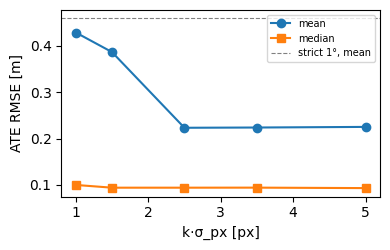

In [12]:
sweep = [("agg_ratio_ks1", 1.0), ("agg_ratio_ks1.5", 1.5), ("agg_ratio", 2.5), ("agg_ratio_ks3.5", 3.5), ("agg_ratio_ks5", 5.0)]
rows = []
for cfg, ks in sweep + [("agg_perp", 2.5)]:
    if cfg not in HAVE or "std_none" not in HAVE: continue
    a, b = ate(cfg), ate("std_none")
    rows.append({"variant": "b_perp/d" if cfg == "agg_perp" else "b/d", "k_sigma_px": ks,
                 "theta_EuRoC": round(ks / FOCAL["euroc"], 4), "theta_TUMVI": round(ks / FOCAL["tumvi"], 4),
                 "mean": a.mean(), "median": a.median(), "worst": a.max(), f"failures > {FAIL_M:g} m": int((a > FAIL_M).sum()),
                 "better_than_strict": int((a < b.reindex(a.index)).sum()),
                 "gate_rejections": int(S[S.config == cfg]["n_gate_rejected"].sum())})
T3 = save(frame(rows, ["variant", "k_sigma_px"]), "sensitivity_k_sigma")
display(T3.round(4))
if len(rows) > 2:
    import matplotlib.pyplot as plt
    sw = [r for r in rows if r["variant"] == "b/d"]
    fig, ax = plt.subplots(figsize=(4, 2.6))
    ax.plot([r["k_sigma_px"] for r in sw], [r["mean"] for r in sw], "o-", label="mean")
    ax.plot([r["k_sigma_px"] for r in sw], [r["median"] for r in sw], "s-", label="median")
    ax.axhline(ate("std_none").mean(), ls="--", c="gray", lw=.8, label="strict 1°, mean")
    ax.set_xlabel("k·σ_px [px]"); ax.set_ylabel("ATE RMSE [m]"); ax.legend(fontsize=7); plt.tight_layout()
    fig.savefig(os.path.join(RESULTS, "fig_sensitivity.png"), dpi=200); plt.show()

### 7.6 Transverse and total baseline on the same candidates
From the per-candidate logs of the loose + criterion runs: how often would b⊥/d and b/d decide differently at the same θ, and how much smaller is b⊥ than b.

In [13]:
def cand(cfg, seq):
    p = os.path.join(RUNS, job_name(cfg, seq) + ".cand.npy")
    return np.load(p) if os.path.isfile(p) else None    # columns: depth, b, b_perp, n_obs, reproj_px, outcome
rows = []
for seq in ALL:
    c = cand("agg_ratio", seq)
    if c is None or not len(c): continue
    th = theta(seq, KS_MAIN); d, b, bp = c[:, 0], c[:, 1], c[:, 2]
    acc_b, acc_p = b / d >= th, bp / d >= th
    rows.append({"sequence": seq, "candidates": len(c), "rejected_by_b/d": int((~acc_b).sum()),
                 "rejected_by_b_perp/d": int((~acc_p).sum()), "disagree": int((acc_b != acc_p).sum()),
                 "disagree_share": float((acc_b != acc_p).mean()), "median_b_perp/b": float(np.median(bp / np.maximum(b, 1e-9)))})
TX = frame(rows, "sequence")
if len(TX):
    tot = TX[["candidates", "rejected_by_b/d", "rejected_by_b_perp/d", "disagree"]].sum()
    TX.loc["ALL"] = [*tot.values, tot["disagree"] / tot["candidates"], TX["median_b_perp/b"].median()]
save(TX, "transverse_agreement", ".4f"); display(TX)

,candidates,rejected_by_b/d,rejected_by_b_perp/d,disagree,disagree_share,median_b_perp/b
sequence,,,,,,
MH_01_easy,40185.0,44.0,83.0,39.0,0.000971,0.793455
MH_02_easy,33636.0,5.0,44.0,39.0,0.001159,0.744589
MH_03_medium,29361.0,27.0,41.0,14.0,0.000477,0.842812
MH_04_difficult,21073.0,13.0,18.0,5.0,0.000237,0.860817
MH_05_difficult,25105.0,28.0,56.0,28.0,0.001115,0.826499
V1_01_easy,37550.0,4.0,16.0,12.0,0.000320,0.862425
V1_02_medium,15978.0,0.0,0.0,0.0,0.000000,0.762631
V1_03_difficult,15207.0,1.0,4.0,3.0,0.000197,0.836817
V2_01_easy,27128.0,3.0,19.0,16.0,0.000590,0.786658


### 7.7 Where candidates leave the admission chain
Counts per configuration, summed over the 17 sequences. Order of the checks: apparent-parallax screen → linear triangulation (DLT) → depth window [0.2, 60] m → Gauss–Newton (positive depth in every view) → inverse depth ρ > 0 → depth window → **criterion** → reprojection ≤ 2 px → χ² test. Negative, near-zero and ill-conditioned depths never reach the criterion.

In [14]:
keys = ["n_tried", "rej_few_views", "rej_parallax", "rej_dlt", "rej_depth_lin", "rej_gn", "rej_rho", "rej_depth",
        "n_gate_rejected", "rej_reproj", "rej_jac", "n_gate_fail", "n_used"]
G = S[S.config.isin(main_cfgs)].groupby("config")[[k for k in keys if k in S.columns]].sum().reindex(main_cfgs)
G = G.rename(columns={"n_gate_rejected": "rej_GATE", "n_gate_fail": "rej_chi2"})
save(G, "guard_counts", ".0f"); display(G)
# landmarks that the loose screen admitted although b/d < theta (what the gate would remove)
rows = []
for seq in ALL:
    c = cand("agg_none", seq)
    if c is None or not len(c): continue
    th = theta(seq, KS_MAIN); used = c[:, 5] == 0; low = c[:, 1] / c[:, 0] < th
    rows.append({"sequence": seq, "used": int(used.sum()), "used_with_b/d<theta": int((used & low).sum()),
                 "share_%": 100 * float((used & low).sum() / max(used.sum(), 1))})
LOW = frame(rows, "sequence"); save(LOW, "loose_admitted_below_theta", ".3f"); display(LOW)

,n_tried,rej_few_views,rej_parallax,rej_dlt,rej_depth_lin,rej_gn,rej_rho,rej_depth,rej_GATE,rej_reproj,rej_jac,rej_chi2,n_used
config,,,,,,,,,,,,,
std_none,456786,0,92007,0,3888,3,14,20,0,5677,0,29,355148
agg_none,456039,0,44143,0,8151,3,20,48,0,4924,0,29,398721
agg_ratio,456343,0,47392,0,4007,3,20,48,1067,4925,0,29,398852
agg_perp,456404,0,47356,0,4213,3,23,47,1898,4947,0,28,397889


,used,used_with_b/d<theta,share_%
sequence,,,
MH_01_easy,39778,44,0.110614
MH_02_easy,33153,3,0.009049
MH_03_medium,28001,24,0.085711
MH_04_difficult,20939,14,0.066861
MH_05_difficult,24873,19,0.076388
V1_01_easy,37427,3,0.008016
V1_02_medium,15824,0,0.000000
V1_03_difficult,15013,1,0.006661
V2_01_easy,26984,1,0.003706


### 7.8 Empirical tracking noise σ_px
Two estimates: (i) the KLT forward–backward error (median over tracks per frame, before the 0.5-px cut; for independent errors it is ≈ √2·σ·1.18 → σ ≈ fb/1.67), and (ii) the mean reprojection error of the triangulated tracks that the filter used (≈ 1.25σ for 2-D Gaussian errors, slightly reduced by the fit).

In [15]:
rows = []
for ds in ("euroc", "tumvi"):
    fb, rp = [], []
    for seq in [s for s in ALL if ds_of(s) == ds]:
        p = os.path.join(RUNS, job_name("agg_ratio", seq) + ".traj.csv")
        if os.path.isfile(p):
            tr = np.loadtxt(p, delimiter=",", skiprows=1)
            if tr.ndim == 2 and tr.shape[1] >= 7:
                fb += list(tr[tr[:, 6] > 0, 6])
        c = cand("agg_ratio", seq)
        if c is not None and len(c):
            rp += list(c[c[:, 5] == 0, 4])
    if fb or rp:
        rows.append({"dataset": ds, "fb_median_px": np.median(fb) if fb else np.nan,
                     "sigma_from_fb_px": np.median(fb) / 1.67 if fb else np.nan,
                     "reproj_mean_px_median": np.median(rp) if rp else np.nan,
                     "sigma_from_reproj_px": np.median(rp) / 1.25 if rp else np.nan})
SIG = save(frame(rows, "dataset"), "sigma_px_estimate", ".3f"); display(SIG)

,fb_median_px,sigma_from_fb_px,reproj_mean_px_median,sigma_from_reproj_px
dataset,,,,
euroc,0.004573,0.002738,0.238328,0.190662
tumvi,0.011901,0.007126,0.373655,0.298924


### 7.9 Cost
In-run cost of the test (timed inside the filter), its share of the per-frame processing time, throughput of runs with and without it, and a micro-benchmark of the expression alone against one triangulation.

In [16]:
R = S[S.config.isin(["agg_none", "agg_ratio", "agg_perp"])].copy()
R["gate_share_%"] = 100 * R["gate_ns"] / 1e6 / (R["frame_ms_mean"] * R["n_frames"])
RT = R.groupby("config")[["gate_us_per_call", "gate_calls", "frame_ms_mean", "fps", "gate_share_%"]].mean()
save(RT, "runtime", ".4f"); display(RT)
r = subprocess.run([sys.executable, os.path.join(CODE, "experiments", "gate_cost.py")], capture_output=True, text=True)
print(r.stdout); open(os.path.join(RESULTS, "gate_cost.txt"), "w").write(r.stdout)

,gate_us_per_call,gate_calls,frame_ms_mean,fps,gate_share_%
config,,,,,
agg_none,NaN,0.000000,74.148294,12.111765,0.000000
agg_perp,96.442176,23809.529412,74.269529,12.082353,1.203444
agg_ratio,36.586000,23816.058824,74.399529,12.058824,0.455561


b/d gate                  7.53 us per call (11 views, Python/NumPy)
b_perp/d gate            13.92 us per call (11 views, Python/NumPy)
full triangulation     1001.05 us per call (11 views, Python/NumPy)
gate / triangulation cost ratio: 0.008



243

### 7.10 Controlled failure cases
Synthetic tracks with known geometry (6 views, landmark at 5 m, σ = 1 px, 500 trials each): lateral motion, tiny lateral motion, axial motion along the ray, rotation only, standstill, an outlier track, a far landmark. The table shows where each track leaves the chain and the depth error of the admitted ones.

In [17]:
out = os.path.join(RESULTS, "failure_cases.csv")
r = subprocess.run([sys.executable, os.path.join(CODE, "experiments", "failure_cases.py"), "--trials", "500", "--out", out],
                   capture_output=True, text=True)
print(r.stdout or r.stderr[-2000:])

theta = 0.0054 rad (k*sigma_px = 2.5 px, f = 460 px), 500 trials per case

gate   case                                  admitted parallax scr depth/GN gua   depth gate reprojection  med.rel.err
none   lateral 0.30 m (b/d = 0.06)              1.000        0.000        0.000        0.000        0.000  0.03
none   lateral 0.01 m (b/d = 0.002)             0.256        0.704        0.040        0.000        0.000  0.589
none   axial 0.50 m along the ray               0.006        0.764        0.230        0.000        0.000  0.893
none   rotation only (5 deg yaw)                0.000        0.764        0.236        0.000        0.000  None
none   standstill (1 mm jitter)                 0.052        0.782        0.166        0.000        0.000  0.793
none   outlier track (one view +3 px)           0.978        0.000        0.000        0.000        0.022  0.033
none   far landmark 80 m, lateral 0.30 m        0.248        0.540        0.212        0.000        0.000  0.442
ratio  lateral 0.

### 7.11 Thresholds without the criterion at the original start

In [18]:
cfgs = [(tag_of(p, "none"), p) for p in THRESHOLDS + [1.5]]
rows = [{"parallax_deg": p, **{k: v for k, v in suite(c).items() if k != "n"}} for c, p in cfgs if c in HAVE and "std_none" in HAVE]
if len(rows) > 2:
    PS = pd.DataFrame(rows).set_index("parallax_deg").sort_index()
    if "agg_ratio" in HAVE:
        PS.loc["0.3 + criterion"] = {k: v for k, v in suite("agg_ratio").items() if k != "n"}
    save(PS, "thresholds_original_start"); display(PS)
else:
    print("tier D is needed for this section")

,mean,median,worst,worst_seq,better_than_strict,failures > 1 m
parallax_deg,,,,,,
0.0,0.219400,0.0932,1.2154,V2_03_difficult,15/17,1
0.1,0.404988,0.0939,3.2876,MH_03_medium,15/17,2
0.2,0.421200,0.0981,3.5409,MH_03_medium,14/17,2
0.3,0.467529,0.0999,4.3324,MH_03_medium,14/17,2
0.5,0.463376,0.1123,3.8822,MH_03_medium,14/17,2
0.7,0.258224,0.1077,1.2663,V2_03_difficult,16/17,1
1.0,0.458806,0.1649,2.6550,room4,-,2
1.5,0.499612,0.1628,2.6553,room4,4/17,3
0.3 + criterion,0.223306,0.0942,1.2171,V2_03_difficult,16/17,1


### 7.12 Rejections near standstills
Share of the rejections by the criterion that fall within 2 s of the start or end of a standstill (a block of at least 20 frames without a filter update), per sequence, in the loose + criterion runs.

In [19]:
WIN, MINLEN = 2.0, 20
def blocks(noupd):
    out, start = [], None
    for i, v in enumerate(noupd):
        if v and start is None: start = i
        elif (not v or i == len(noupd) - 1) and start is not None:
            if i - start >= MINLEN: out.append((start, i - 1))
            start = None
    return out
rows = []
for seq in ALL:
    p = os.path.join(RUNS, job_name("agg_ratio", seq) + ".traj.csv")
    if not os.path.isfile(p): continue
    tr = np.loadtxt(p, delimiter=",", skiprows=1)
    if tr.ndim != 2 or tr.shape[1] < 6: continue
    t, innov, rejf = tr[:, 0], tr[:, 4], tr[:, 5]
    bl = blocks(innov < 0); bnd = [t[a] for a, b in bl] + [t[b] for a, b in bl]
    near = np.array([any(abs(ti - x) <= WIN for x in bnd) for ti in t]) if bnd else np.zeros(len(t), bool)
    n_rej = int(rejf.sum()); n_near = int(rejf[near].sum())
    rows.append({"sequence": seq, "standstill_blocks": len(bl), "rejections": n_rej, "within_2s": n_near,
                 "share_rej": n_near / n_rej if n_rej else np.nan, "share_frames": near.mean()})
ST = frame(rows, "sequence"); save(ST, "rejections_near_standstill"); display(ST)

,standstill_blocks,rejections,within_2s,share_rej,share_frames
sequence,,,,,
MH_01_easy,4,44,10,0.227273,0.105906
MH_02_easy,1,5,0,0.000000,0.057123
MH_03_medium,3,27,25,0.925926,0.126257
MH_04_difficult,3,13,12,0.923077,0.156173
MH_05_difficult,2,28,3,0.107143,0.120957
V1_01_easy,2,4,1,0.250000,0.062696
V1_02_medium,1,0,0,NaN,0.071976
V1_03_difficult,2,1,1,1.000000,0.096064
V2_01_easy,2,3,3,1.000000,0.105960


### 7.13 Illustration: MH_03 position error without and with the criterion
Not printed in the paper. Needs the MH_03 data and the two runs at the original start.

In [20]:
import matplotlib
sys.path.insert(0, os.path.join(CODE, "charts"))
try:
    import make_figures as mf
    mf.FIG = RESULTS
    if os.path.isfile(os.path.join(RUNS, "agg_none__MH_03_medium.traj.csv")) and ready("MH_03_medium"):
        mf.fig_mh03(RUNS, os.path.join(DATA, "euroc"))
        from IPython.display import Image, display as _d; _d(Image(os.path.join(RESULTS, "fig2_mh03.png")))
    else:
        print("MH_03 runs or data not available")
except Exception as e:
    print("figure skipped:", type(e).__name__, e)

MH_03 runs or data not available


## 8. Numbers quoted in the paper
One text file with the values quoted in the paper, and a zip of `results/` for archiving.

In [21]:
L = []
def line(s): L.append(s); print(s)
G_ = globals()
if all(G_.get(k) is not None for k in ("STRICT", "LOOSE", "CRIT")):
    for k, v in (("strict", STRICT), ("loose", LOOSE), ("loose + criterion", CRIT)):
        line(f"{k}: median ATE over 51 runs {np.median(v.values):.3f} m, runs above 1 m {(v.values > FAIL_M).sum()}, "
             f"original start mean {v[0.0].mean():.3f} m, median {v[0.0].median():.3f} m")
    for pr, row in P51.iterrows():
        line(f"Paired {pr}: runs better / worse / equal {row['runs better / worse / equal']}, median difference {row.median_diff_m:+.4f} m "
             f"(95% interval {row.median_CI95}), p = {row.p_runs:.2g} over runs; sequence medians better {row['sequence medians better']}, "
             f"p = {row.p_medians:.2g}")
if len(G_.get("T2S", [])):
    for par, r in T2S.iterrows():
        line(f"Threshold {par:g} deg, alone / with criterion: median {r.median_alone:.3f} / {r.median_with:.3f} m, runs above 1 m "
             f"{r.above_1m_alone} / {r.above_1m_with}, worst MH_03 run {r.MH_03_worst_alone:.2f} / {r.MH_03_worst_with:.2f} m, "
             f"rejected per run {r.rejected_per_run:.0f} ({r['rejected_share_%']:.2f} %), with vs alone p = {r.p_runs:.2f}")
if "agg_ratio" in HAVE and len(G_.get("TX", [])):
    line(f"Original start: criterion rejects {int(S[S.config == 'agg_ratio'].n_gate_rejected.sum())} of "
         f"{int(TX.loc['ALL', 'candidates'])} candidates")
if len(G_.get("T3", [])): line("Sensitivity, original start: " + "; ".join(
        f"k*sigma = {ks:g} px ({v}): mean {r['mean']:.3f}, median {r['median']:.3f}, above 1 m {r[f'failures > {FAIL_M:g} m']}"
        for (v, ks), r in T3.iterrows()))
if len(G_.get("TX", [])): line(f"b and b_perp: decisions differ on {100 * TX.loc['ALL', 'disagree_share']:.2f} % of candidates; "
                               f"median b_perp/b = {TX.loc['ALL', 'median_b_perp/b']:.2f}")
if len(G_.get("RT", [])): line("Cost: " + "; ".join(f"{c}: {r.gate_us_per_call:.2f} us per test, {r['gate_share_%']:.3f} % of frame time, "
                                                    f"{r.frame_ms_mean:.1f} ms per frame" for c, r in RT.iterrows() if r.gate_calls > 0))
if len(G_.get("SIG", [])): line("sigma_px: " + "; ".join(f"{d}: {r.sigma_from_fb_px:.2f} px (forward-backward), "
                                                         f"{r.sigma_from_reproj_px:.2f} px (reprojection)" for d, r in SIG.iterrows()))
if len(G_.get("ST", [])) and "MH_03_medium" in ST.index:
    r = ST.loc["MH_03_medium"]; line(f"MH_03: {int(r.within_2s)} of {int(r.rejections)} rejections within 2 s of a standstill boundary")
open(os.path.join(RESULTS, "paper_numbers.txt"), "w", encoding="utf-8").write("\n".join(L) + "\n")
shutil.make_archive(os.path.join(STUDY, "results"), "zip", RESULTS)
print("\nwritten:", os.path.join(RESULTS, "paper_numbers.txt"), "and", os.path.join(STUDY, "results.zip"))

strict: median ATE over 51 runs 0.157 m, runs above 1 m 8, original start mean 0.459 m, median 0.165 m
loose: median ATE over 51 runs 0.116 m, runs above 1 m 6, original start mean 0.468 m, median 0.100 m
loose + criterion: median ATE over 51 runs 0.096 m, runs above 1 m 6, original start mean 0.223 m, median 0.094 m
Paired loose + criterion vs strict: runs better / worse / equal 45 / 6 / 0, median difference -0.0089 m (95% interval -0.0562 to -0.0038), p = 1.7e-07 over runs; sequence medians better 15 of 17, p = 0.00029
Paired loose vs strict: runs better / worse / equal 39 / 12 / 0, median difference -0.0062 m (95% interval -0.0569 to -0.0014), p = 0.00022 over runs; sequence medians better 13 of 17, p = 0.017
Paired loose + criterion vs loose: runs better / worse / equal 20 / 19 / 12, median difference +0.0000 m (95% interval -0.0004 to +0.0001), p = 0.3 over runs; sequence medians better 7 of 17, p = 0.78
Threshold 0 deg, alone / with criterion: median 0.094 / 0.095 m, runs above 1